# Autoregressive Word-Level Text Generation: SimpleRNN vs Bidirectional RNN vs LSTM vs GRU
**Course:** Foundations of Generative AI (ICT4403) · **Assignment 2**

**Dataset:** Tiny Shakespeare (Karpathy, *char-rnn*) – https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

**Goal:** train four recurrent architectures under identical conditions to predict the next word, then generate text from the same seeds at several sampling temperatures and compare them quantitatively (loss, perplexity, accuracy, training time) and qualitatively (coherence, diversity, repetition).

## 0. Setup

In [1]:
import os, re, time, json, random, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from collections import Counter

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs('results', exist_ok=True)
print('TensorFlow', tf.__version__)

I0000 00:00:1791990059.546159     233 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791990059.807886     233 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791990062.343749     233 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Dataset: description and preprocessing
**Tiny Shakespeare** is a ~1.1 MB plain-text file with a concatenation of plays by William Shakespeare (speaker names followed by dialogue in early-modern English verse). It is a classic benchmark for language modelling because it has strong local structure (speaker labels, line breaks, archaic vocabulary, punctuation) but is small enough to train on a laptop.

In [2]:
URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
if not os.path.exists('tinyshakespeare.txt'):
    urllib.request.urlretrieve(URL, 'tinyshakespeare.txt')
raw = open('tinyshakespeare.txt', encoding='utf-8').read()
print('Characters:', len(raw), '| Lines:', raw.count('\n'))
print(raw[:400])

Characters: 1115394 | Lines: 40000
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it 


### 1.1 Pre-processing
1. Lower-case everything (reduces vocabulary size).
2. Tokenise into **words**, **punctuation marks** (`. , ! ? ; :`) and a special `<nl>` token for line breaks (so that the model can learn verse/speaker structure). Apostrophes inside words (e.g. *o'er*) are kept.
3. Keep the top `MAX_VOCAB` most frequent tokens; all others become `<unk>`. Index 0 is reserved for padding.
4. **Chronological split** 90 % train / 5 % validation / 5 % test *before* windowing, so that overlapping windows never leak across splits.

In [3]:
text = raw.lower().replace('\n', ' <nl> ')
tokens = re.findall(r"<nl>|[a-z]+(?:'[a-z]+)*|[.,!?;:]", text)
print('Total tokens:', len(tokens), '| Unique tokens:', len(set(tokens)))

MAX_VOCAB = 3000
freq = Counter(tokens)
vocab = ['<pad>', '<unk>'] + [w for w, _ in freq.most_common(MAX_VOCAB - 2)]
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
V = len(vocab)
ids = np.array([word2idx.get(t, 1) for t in tokens], dtype=np.int32)
coverage = (ids != 1).mean()
print(f'Vocabulary size V = {V}; token coverage = {coverage:.2%}; <unk> rate = {1-coverage:.2%}')
print('Most common tokens:', freq.most_common(12))

Total tokens: 290145 | Unique tokens: 12380


Vocabulary size V = 3000; token coverage = 94.30%; <unk> rate = 5.70%
Most common tokens: [('<nl>', 40000), (',', 19846), (':', 10316), ('.', 7885), ('the', 6287), ('and', 5690), ('to', 4902), ('i', 4664), ('of', 3759), (';', 3628), ('you', 3149), ('my', 3120)]


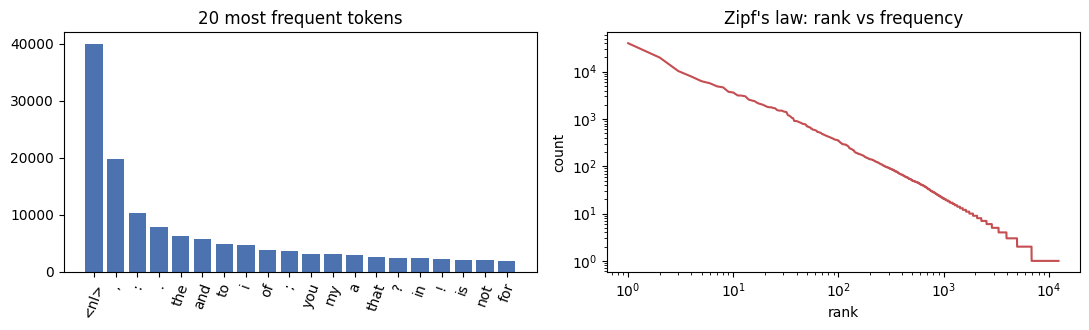

In [4]:
# Dataset characteristics plot
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
top = freq.most_common(20)
ax[0].bar([w for w,_ in top], [c for _,c in top], color='#4C72B0'); ax[0].set_title('20 most frequent tokens')
ax[0].tick_params(axis='x', rotation=70)
ranks = np.arange(1, len(freq)+1); counts = np.array(sorted(freq.values(), reverse=True))
ax[1].loglog(ranks, counts, color='#C44E52'); ax[1].set_title("Zipf's law: rank vs frequency"); ax[1].set_xlabel('rank'); ax[1].set_ylabel('count')
plt.tight_layout(); plt.savefig('results/dataset_characteristics.png', dpi=150); plt.show()

### 1.2 Input–target sequences (autoregressive set-up)
For every window of `SEQ_LEN = 20` consecutive tokens (input **X**), the target **y** is the token that immediately follows. This realises the autoregressive factorisation  P(w₁…w_T) = ∏ P(w_t | w_{<t}). Windows slide with `STRIDE = 3` to limit the amount of (highly overlapping) data and keep training fast on CPU.

In [5]:
SEQ_LEN, STRIDE = 20, 3
n = len(ids)
a, b = int(n*0.90), int(n*0.95)
def make_xy(arr, stride=STRIDE):
    starts = np.arange(0, len(arr) - SEQ_LEN, stride)
    X = np.stack([arr[s:s+SEQ_LEN] for s in starts])
    y = np.array([arr[s+SEQ_LEN] for s in starts])
    return X, y
Xtr, ytr = make_xy(ids[:a]); Xva, yva = make_xy(ids[a:b]); Xte, yte = make_xy(ids[b:])
print('Train', Xtr.shape, '| Val', Xva.shape, '| Test', Xte.shape)
print('Example input :', ' '.join(idx2word[i] for i in Xtr[0]))
print('Example target:', idx2word[ytr[0]])

Train (87037, 20) | Val (4829, 20) | Test (4830, 20)
Example input : first citizen : <nl> before we proceed any further , hear me speak . <nl> <nl> all : <nl> speak
Example target: ,


## 2. Models (identical conditions)
All models share: `Embedding(V, 100, mask_zero=True)` → recurrent layer with **128 units** → `Dropout(0.3)` → `Dense(V, softmax)`; Adam (lr = 1e-3, clipnorm = 1), batch 256, max 10 epochs, early stopping on validation loss (patience 2, best weights restored), same random seed.
* **SimpleRNN** – plain Elman recurrence (tanh).
* **Bidirectional RNN** – `Bidirectional(SimpleRNN(128))`; reads the *input context window* forwards and backwards (output 256-d). No future tokens leak because only the already-known context is read backwards.
* **LSTM** – gated cell with separate cell state (input/forget/output gates).
* **GRU** – lighter gated unit (update/reset gates).

In [6]:
EMB, UNITS, BATCH, EPOCHS = 100, 128, 256, 10

def build(kind):
    rnn = {'SimpleRNN': lambda: layers.SimpleRNN(UNITS),
           'BiRNN':     lambda: layers.Bidirectional(layers.SimpleRNN(UNITS)),
           'LSTM':      lambda: layers.LSTM(UNITS),
           'GRU':       lambda: layers.GRU(UNITS)}[kind]()
    m = models.Sequential([
        layers.Input(shape=(SEQ_LEN,)),
        layers.Embedding(V, EMB, mask_zero=True),
        rnn,
        layers.Dropout(0.3),
        layers.Dense(V, activation='softmax')], name=kind)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(5, name='top5')])
    return m

KINDS = ['SimpleRNN', 'BiRNN', 'LSTM', 'GRU']
for k in KINDS: print(k, 'parameters:', f'{build(k).count_params():,}')

SimpleRNN parameters: 716,312
BiRNN parameters: 1,129,624
LSTM parameters: 804,248


GRU parameters: 775,320


## 3. Training

In [7]:
trained, hist, train_time, epochs_run = {}, {}, {}, {}
for k in KINDS:
    tf.keras.backend.clear_session(); tf.random.set_seed(SEED); np.random.seed(SEED)
    m = build(k)
    es = callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
    t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=BATCH,
              callbacks=[es], verbose=2)
    train_time[k] = time.time() - t0
    trained[k], hist[k], epochs_run[k] = m, h.history, len(h.history['loss'])
    m.save_weights(f'results/{k}.weights.h5')
    print(f'>>> {k}: {train_time[k]:.0f}s, {epochs_run[k]} epochs\n')
json.dump(hist, open('results/training_history.json', 'w'))

Epoch 1/10


E0000 00:00:1791990066.469775     233 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


340/340 - 11s - 34ms/step - accuracy: 0.1512 - loss: 5.4529 - top5: 0.3211 - val_accuracy: 0.2127 - val_loss: 4.9212 - val_top5: 0.3790


Epoch 2/10


340/340 - 10s - 29ms/step - accuracy: 0.2175 - loss: 4.8354 - top5: 0.3704 - val_accuracy: 0.2638 - val_loss: 4.5576 - val_top5: 0.4156


...

Epoch 9/10


340/340 - 21s - 62ms/step - accuracy: 0.2843 - loss: 3.9510 - top5: 0.4673 - val_accuracy: 0.2889 - val_loss: 4.2180 - val_top5: 0.4666


Epoch 10/10


340/340 - 40s - 119ms/step - accuracy: 0.2898 - loss: 3.8858 - top5: 0.4728 - val_accuracy: 0.2878 - val_loss: 4.2207 - val_top5: 0.4695


>>> GRU: 227s, 10 epochs



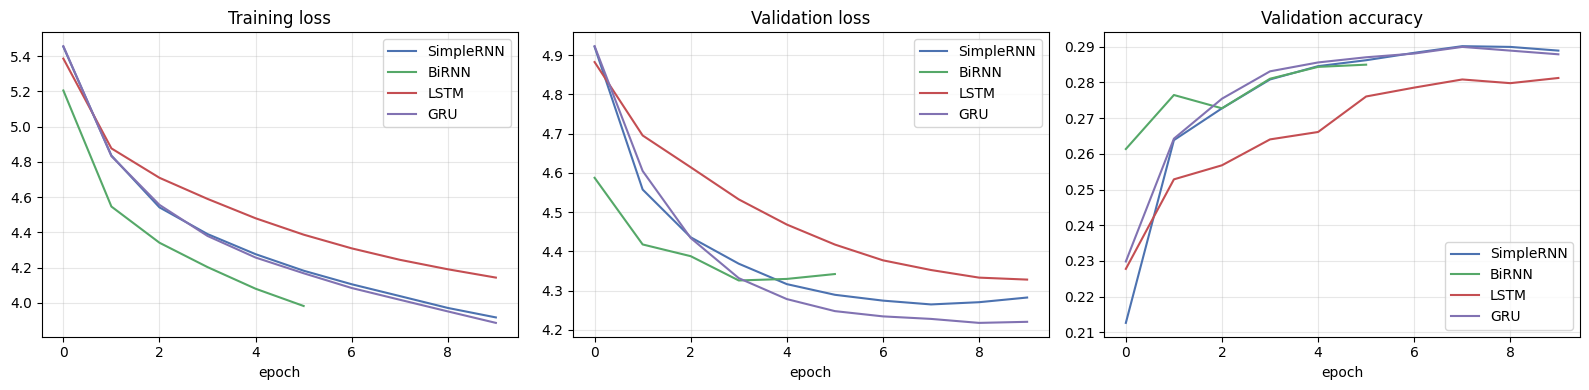

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
col = dict(zip(KINDS, ['#4C72B0', '#55A868', '#C44E52', '#8172B2']))
for k in KINDS:
    ax[0].plot(hist[k]['loss'], color=col[k], label=k)
    ax[1].plot(hist[k]['val_loss'], color=col[k], label=k)
    ax[2].plot(hist[k]['val_accuracy'], color=col[k], label=k)
for a_, t in zip(ax, ['Training loss', 'Validation loss', 'Validation accuracy']):
    a_.set_title(t); a_.set_xlabel('epoch'); a_.legend(); a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig('results/training_curves.png', dpi=150); plt.show()

## 4. Quantitative evaluation on the held-out test set
Perplexity = exp(cross-entropy loss): the effective number of words the model is "choosing between" at each step (lower is better).

In [9]:
rows = []
for k in KINDS:
    loss, acc, top5 = trained[k].evaluate(Xte, yte, batch_size=512, verbose=0)
    rows.append(dict(Model=k, Params=trained[k].count_params(), Epochs=epochs_run[k],
                     TrainTime_s=round(train_time[k], 1),
                     TrainLoss=round(hist[k]['loss'][-1], 3), ValLoss=round(min(hist[k]['val_loss']), 3),
                     TestLoss=round(loss, 3), TestPerplexity=round(float(np.exp(loss)), 1),
                     Top1Acc=round(acc*100, 2), Top5Acc=round(top5*100, 2)))
metrics = pd.DataFrame(rows).set_index('Model')
metrics.to_csv('results/quantitative_metrics.csv'); metrics

,Params,Epochs,TrainTime_s,TrainLoss,ValLoss,TestLoss,TestPerplexity,Top1Acc,Top5Acc
Model,,,,,,,,,
SimpleRNN,716312,10,102.8,3.917,4.265,4.546,94.2,28.43,44.74
BiRNN,1129624,6,125.0,3.982,4.326,4.616,101.0,27.25,43.54
LSTM,804248,10,225.5,4.143,4.328,4.638,103.3,26.67,44.37
GRU,775320,10,227.0,3.886,4.218,4.493,89.4,28.86,45.57


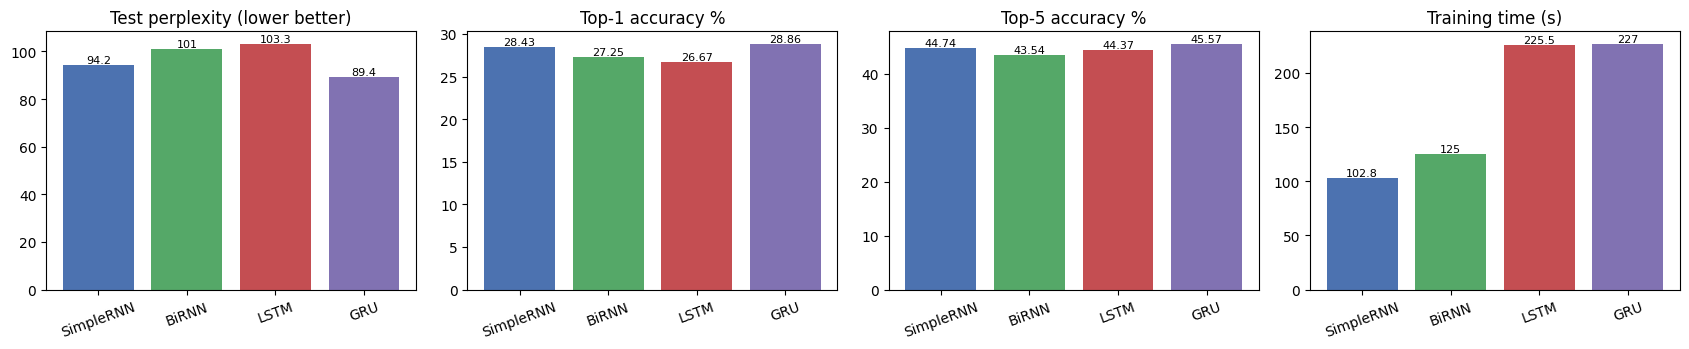

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a_, c, t in zip(ax, ['TestPerplexity', 'Top1Acc', 'Top5Acc', 'TrainTime_s'],
                    ['Test perplexity (lower better)', 'Top-1 accuracy %', 'Top-5 accuracy %', 'Training time (s)']):
    a_.bar(metrics.index, metrics[c], color=[col[k] for k in metrics.index]); a_.set_title(t)
    a_.tick_params(axis='x', rotation=20)
    for i, v in enumerate(metrics[c]): a_.text(i, v, f'{v:g}', ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.savefig('results/metric_comparison.png', dpi=150); plt.show()

## 5. Text generation with temperature sampling
Autoregressive loop: feed the last 20 tokens → get a distribution over the vocabulary → rescale logits by temperature **T** (`p ∝ p^{1/T}`) → sample a token → append → repeat.
* **T < 1** sharpens the distribution (safer, more repetitive); **T = 1** is the model's own distribution; **T > 1** flattens it (more diverse, more errors).
* `<pad>` and `<unk>` are never sampled.

Same three seeds and the same random generator seed are used for every model.

In [11]:
SEEDS = ["first citizen : <nl> before we proceed any further , hear me speak . <nl>",
         "romeo : <nl> o , she doth teach the torches to burn bright ! <nl>",
         "my lord , the king is dead and all the court doth weep . <nl>"]
TEMPS = [0.5, 1.0, 1.5]
GEN_LEN, N_SAMPLES = 50, 6          # words per sample; samples per (seed, T) for the statistics

def encode_seed(s):
    t = re.findall(r"<nl>|[a-z]+(?:'[a-z]+)*|[.,!?;:]", s.lower())
    i = [word2idx.get(w, 1) for w in t][-SEQ_LEN:]
    return [0]*(SEQ_LEN - len(i)) + i

def sample(model, seeds_ids, T, length, rng):
    ctx = np.array(seeds_ids, dtype=np.int32); out = [[] for _ in ctx]
    for _ in range(length):
        p = model(ctx, training=False).numpy().astype('float64')
        p[:, :2] = 0                                   # never emit <pad>/<unk>
        p = np.exp(np.log(p + 1e-12) / T); p /= p.sum(1, keepdims=True)
        nxt = np.array([rng.choice(V, p=pi) for pi in p])
        ctx = np.concatenate([ctx[:, 1:], nxt[:, None]], 1)
        for o, w in zip(out, nxt): o.append(idx2word[w])
    return out

def detok(ws):
    s = ' '.join(ws).replace(' <nl> ', '\n').replace('<nl>', '\n')
    return re.sub(r' ([.,!?;:])', r'\1', s)

gen = {}   # gen[model][T] = list over seeds of list of N_SAMPLES token lists
for k in KINDS:
    gen[k] = {}
    for T in TEMPS:
        rng = np.random.default_rng(SEED)
        batch = [encode_seed(s) for s in SEEDS for _ in range(N_SAMPLES)]
        outs = sample(trained[k], batch, T, GEN_LEN, rng)
        gen[k][T] = [outs[i*N_SAMPLES:(i+1)*N_SAMPLES] for i in range(len(SEEDS))]
print('generation done')

generation done


In [12]:
# Save and show one sample per (model, temperature, seed)
lines = ['# Generated text samples\n']
for si, s in enumerate(SEEDS):
    lines.append(f'\n## Seed {si+1}: `{s}`\n')
    for T in TEMPS:
        lines.append(f'\n### Temperature {T}\n')
        for k in KINDS:
            lines.append(f'**{k}**\n\n```\n{detok(gen[k][T][si][0])}\n```\n')
open('results/generated_samples.md', 'w').write('\n'.join(lines))
for T in TEMPS:
    print('='*25, f'T = {T}', '='*25)
    for k in KINDS:
        print(f'--- {k} ---\n{detok(gen[k][T][0][0])}\n')

========================= T = 0.5 =========================
--- SimpleRNN ---

 lucio:
o, i will not the majesty,
which is the crown, my lord and
your duke of the time of the king!

 king henry vi:
what, good lord,
i, sir, and go

--- BiRNN ---

 being vincentio:
i have you!

 king richard ii:
what, sir, go, sir, shall i have not a king richard
that, therefore he shall so as and you,

 duke of york:
why

--- LSTM ---

 leontes:
o, and i will not thy.

 gloucester:
i must have speak, as the word,
and in the native that should, let him.

 king richard iii:
i, then, and make

--- GRU ---

 camillo:
o, i will not the tower,
if you is a gentleman of his fine.

 juliet:
you will not further.

 shepherd:
o, i am a man, and, sir,
if

========================= T = 1.0 =========================
--- SimpleRNN ---

 volumnia:
earth, i do him the tremble,
wherefore some my warrant: where one cheek i days
o, you do have in goods to prey
direct pure pay such power, but this than
a my trade.
o

--- Bi

### 5.1 Quantifying qualitative properties
Since coherence cannot be measured exactly, we use transparent proxies computed over all generated samples (3 seeds × 6 samples × 50 words per cell):
* **Distinct-1 / Distinct-2** – share of unique unigrams / bigrams (diversity; higher = more varied).
* **Repetition rate** – share of trigrams that already appeared earlier in the *same* sample (lower = less looping).
* **Max word run / immediate repeats** – fraction of positions where a token equals the previous token.
* **Bigram validity** – share of generated bigrams that actually occur in the training corpus (a proxy for local grammaticality / contextual consistency).

In [13]:
train_bigrams = set(zip(tokens[:a], tokens[1:a]))
def ngrams(w, n): return list(zip(*[w[i:] for i in range(n)]))
def stats(samples):
    d1, d2, rep, imm, valid = [], [], [], [], []
    for w in samples:
        u1, u2, t3 = w, ngrams(w, 2), ngrams(w, 3)
        d1.append(len(set(u1))/len(u1)); d2.append(len(set(u2))/len(u2))
        rep.append(1 - len(set(t3))/len(t3))
        imm.append(np.mean([w[i] == w[i-1] for i in range(1, len(w))]))
        valid.append(np.mean([b in train_bigrams for b in u2]))
    return dict(Distinct1=np.mean(d1), Distinct2=np.mean(d2), TrigramRepeat=np.mean(rep),
                ImmediateRepeat=np.mean(imm), BigramValid=np.mean(valid))
rows = []
for k in KINDS:
    for T in TEMPS:
        flat = [s for per_seed in gen[k][T] for s in per_seed]
        rows.append(dict(Model=k, Temp=T, **{m: round(v, 3) for m, v in stats(flat).items()}))
gstats = pd.DataFrame(rows); gstats.to_csv('results/generation_statistics.csv', index=False)
gstats.pivot(index='Model', columns='Temp', values=['Distinct2', 'TrigramRepeat', 'BigramValid']).round(3)

Distinct2               TrigramRepeat             BigramValid  \
Temp            0.5    1.0    1.5           0.5    1.0  1.5         0.5   
Model                                                                     
BiRNN         0.871  0.974  0.997         0.030  0.000  0.0       0.923   
GRU           0.873  0.958  0.989         0.038  0.002  0.0       0.958   
LSTM          0.855  0.954  0.990         0.049  0.005  0.0       0.948   
SimpleRNN     0.868  0.967  0.994         0.039  0.005  0.0       0.963   

                         
Temp         1.0    1.5  
Model                    
BiRNN      0.673  0.350  
GRU        0.730  0.405  
LSTM       0.732  0.439  
SimpleRNN  0.710  0.438

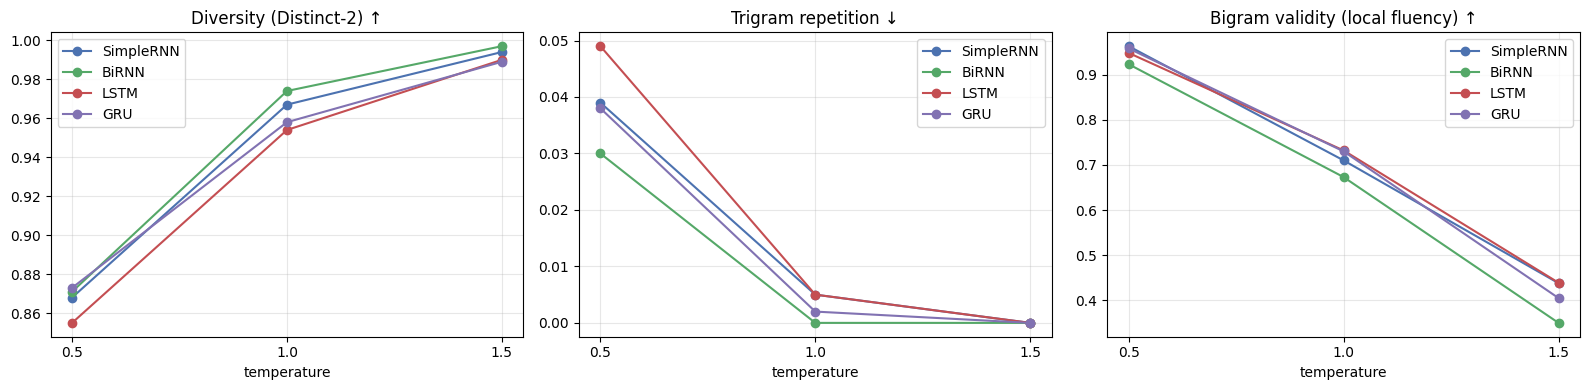

,Model,Temp,Distinct1,Distinct2,TrigramRepeat,ImmediateRepeat,BigramValid
0,SimpleRNN,0.5,0.546,0.868,0.039,0.025,0.963
1,SimpleRNN,1.0,0.723,0.967,0.005,0.019,0.710
2,SimpleRNN,1.5,0.853,0.994,0.000,0.006,0.438
3,BiRNN,0.5,0.542,0.871,0.030,0.024,0.923
4,BiRNN,1.0,0.746,0.974,0.000,0.012,0.673
5,BiRNN,1.5,0.886,0.997,0.000,0.005,0.350
6,LSTM,0.5,0.529,0.855,0.049,0.023,0.948
7,LSTM,1.0,0.712,0.954,0.005,0.026,0.732
8,LSTM,1.5,0.850,0.990,0.000,0.007,0.439
9,GRU,0.5,0.579,0.873,0.038,0.027,0.958


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a_, m, t in zip(ax, ['Distinct2', 'TrigramRepeat', 'BigramValid'],
                    ['Diversity (Distinct-2) ↑', 'Trigram repetition ↓', 'Bigram validity (local fluency) ↑']):
    for k in KINDS:
        d = gstats[gstats.Model == k]; a_.plot(d.Temp, d[m], marker='o', color=col[k], label=k)
    a_.set_title(t); a_.set_xlabel('temperature'); a_.set_xticks(TEMPS); a_.grid(alpha=.3); a_.legend()
plt.tight_layout(); plt.savefig('results/temperature_analysis.png', dpi=150); plt.show()
gstats

## 6. Overall ranking
A simple composite: rank each model on test perplexity, top-1 accuracy, training time (efficiency) and — at T = 1.0 — bigram validity, diversity (Distinct-2) and low repetition; lower mean rank = better overall.

In [15]:
g1 = gstats[gstats.Temp == 1.0].set_index('Model')
rk = pd.DataFrame({'Perplexity': metrics.TestPerplexity.rank(), 'Top1Acc': (-metrics.Top1Acc).rank(),
                   'TrainTime': metrics.TrainTime_s.rank(), 'BigramValid(T=1)': (-g1.BigramValid).rank(),
                   'Distinct2(T=1)': (-g1.Distinct2).rank(), 'Repetition(T=1)': g1.TrigramRepeat.rank()})
rk['MeanRank'] = rk.mean(1); rk = rk.sort_values('MeanRank'); rk.to_csv('results/overall_ranking.csv')
print(rk.round(2)); print('\nBest overall:', rk.index[0])

           Perplexity  Top1Acc  TrainTime  BigramValid(T=1)  Distinct2(T=1)  \
Model                                                                         
GRU               1.0      1.0        4.0               2.0             3.0   
SimpleRNN         2.0      2.0        1.0               3.0             2.0   
BiRNN             3.0      3.0        2.0               4.0             1.0   
LSTM              4.0      4.0        3.0               1.0             4.0   

           Repetition(T=1)  MeanRank  
Model                                 
GRU                    2.0      2.17  
SimpleRNN              3.5      2.25  
BiRNN                  1.0      2.33  
LSTM                   3.5      3.25  

Best overall: GRU


/tmp/ipykernel_233/1493690540.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  rk['MeanRank'] = rk.mean(1); rk = rk.sort_values('MeanRank'); rk.to_csv('results/overall_ranking.csv')
